# Q2-Q3 - Actual architectures and empirical optimisation
Inspect the measured study without rerunning selection or touching the held-out set.

In [1]:
from pathlib import Path
import sys, json
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks': PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src'))
from fabric_inspector.common import read_json
from IPython.display import display, Image as DisplayImage, Markdown
import pandas as pd
def read(path): return read_json(PROJECT / path)
def figure(path): display(DisplayImage(filename=str(PROJECT / path)))


In [2]:
bundle=read('artifacts/serving-bundle.json')
initial=read('experiments/ann-search-000.json')
final=read('experiments/'+bundle['run_id']+'.json')
for run in [initial,final]:
    print(run['run_id'], run['architecture']['total_parameters'], 'parameters')
    display(pd.DataFrame(run['architecture']['layers']))

ann-search-000 5977 parameters
ann-search-018 1518881 parameters


,layer,type,input,output,parameters
0,features.0.0,Conv2d,"[1, 1, 256, 256]","[1, 8, 256, 256]",72
1,features.0.1,BatchNorm2d,"[1, 8, 256, 256]","[1, 8, 256, 256]",16
2,features.0.2,ReLU,"[1, 8, 256, 256]","[1, 8, 256, 256]",0
3,features.0.3,MaxPool2d,"[1, 8, 256, 256]","[1, 8, 128, 128]",0
4,features.1.0,Conv2d,"[1, 8, 128, 128]","[1, 16, 128, 128]",1152
5,features.1.1,BatchNorm2d,"[1, 16, 128, 128]","[1, 16, 128, 128]",32
6,features.1.2,ReLU,"[1, 16, 128, 128]","[1, 16, 128, 128]",0
7,features.1.3,MaxPool2d,"[1, 16, 128, 128]","[1, 16, 64, 64]",0
8,features.2.0,Conv2d,"[1, 16, 64, 64]","[1, 32, 64, 64]",4608
9,features.2.1,BatchNorm2d,"[1, 32, 64, 64]","[1, 32, 64, 64]",64


,layer,type,input,output,parameters
0,network.features.0.0,Conv2d,"[1, 3, 256, 256]","[1, 16, 128, 128]",432
1,network.features.0.1,BatchNorm2d,"[1, 16, 128, 128]","[1, 16, 128, 128]",32
2,network.features.0.2,Hardswish,"[1, 16, 128, 128]","[1, 16, 128, 128]",0
3,network.features.1.block.0.0,Conv2d,"[1, 16, 128, 128]","[1, 16, 64, 64]",144
4,network.features.1.block.0.1,BatchNorm2d,"[1, 16, 64, 64]","[1, 16, 64, 64]",32
...,...,...,...,...,...
136,network.avgpool,AdaptiveAvgPool2d,"[1, 576, 8, 8]","[1, 576, 1, 1]",0
137,network.classifier.0,Linear,"[1, 576]","[1, 1024]",590848
138,network.classifier.1,Hardswish,"[1, 1024]","[1, 1024]",0
139,network.classifier.2,Dropout,"[1, 1024]","[1, 1024]",0


,run_id,family,status,started_at,finished_at,seed,split_sha256,code_sha256,hypothesis,config,epochs_completed,selected_epoch,validation_f2,validation_ap,tp,fp,fn,training_seconds,checkpoint,checkpoint_sha256,outcome,lesson
0,ann-search-000,ANN,COMPLETE,2026-10-11T15:55:11.143583+00:00,2026-10-11T16:09:12.390456+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,957ae7314bb73c845ce8f09375c09bbf71921f13a5c9e4...,A small spatial CNN can learn local weave disc...,"{""augment"": true, ""batch_size"": 32, ""cpu_threa...",4.0,1.0,0.092259,0.018772,41,1973,11,841.229277,artifacts/ann-search-000.pt,04dc4be28f565255c99b54e8d7b56a1ac1d0ff3d9e7521...,Measured validation evidence; no test-driven c...,"Validation F2=0.0923, AP=0.0188, TP/FP/FN=41/1..."
1,ann-search-001,ANN,COMPLETE,2026-10-11T16:09:15.578824+00:00,2026-10-11T16:16:38.694093+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,957ae7314bb73c845ce8f09375c09bbf71921f13a5c9e4...,AdamW learning-rate comparison at 0.0001,"{""augment"": true, ""batch_size"": 32, ""cpu_threa...",4.0,3.0,0.080402,0.013982,48,2729,4,443.101177,artifacts/ann-search-001.pt,fed932b889e8b0c4ba379ec615374a960d129b97ad2951...,Measured validation evidence; no test-driven c...,"Validation F2=0.0804, AP=0.0140, TP/FP/FN=48/2..."
2,ann-search-002,ANN,COMPLETE,2026-10-11T16:17:00.710513+00:00,2026-10-11T16:26:50.351144+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,5c693e1705f86d9c1ec2bf49173c621663aa7d7b5d379d...,AdamW learning-rate comparison at 0.0003,"{""augment"": true, ""batch_size"": 32, ""cpu_threa...",4.0,1.0,0.094131,0.016496,17,678,35,589.617536,artifacts/ann-search-002.pt,fa3dcea5fadfa2a552dbf875d9197fc218dc8c150599ba...,Measured validation evidence; no test-driven c...,"Validation F2=0.0941, AP=0.0165, TP/FP/FN=17/6..."
3,ann-search-003,ANN,COMPLETE,2026-10-11T16:29:08.627909+00:00,2026-10-11T16:36:39.413284+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,c6224cc471b77be2ba46336eafd611d99f54512518db2a...,AdamW learning-rate comparison at 0.003,"{""augment"": true, ""batch_size"": 32, ""cpu_threa...",4.0,2.0,0.088134,0.015271,41,2077,11,450.770482,artifacts/ann-search-003.pt,766f02ff9ca843a6c25e15cbfd0ac395b15210c404f080...,Measured validation evidence; no test-driven c...,"Validation F2=0.0881, AP=0.0153, TP/FP/FN=41/2..."
4,ann-search-004,ANN,COMPLETE,2026-10-11T16:36:42.372158+00:00,2026-10-11T16:44:18.228078+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,c6224cc471b77be2ba46336eafd611d99f54512518db2a...,Batch-size comparison at 16,"{""augment"": true, ""batch_size"": 16, ""cpu_threa...",4.0,1.0,0.089481,0.017042,41,2042,11,455.844069,artifacts/ann-search-004.pt,9d7d436b786ac49b31bf0160e9d764450bab77e9e495f8...,Measured validation evidence; no test-driven c...,"Validation F2=0.0895, AP=0.0170, TP/FP/FN=41/2..."
5,ann-search-005,ANN,COMPLETE,2026-10-11T18:54:39.659211+00:00,2026-10-11T19:01:25.330458+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,c954f67c727244417c2ebd7cb09a7f0a477c267d97d210...,Batch-size comparison at 64,"{""augment"": true, ""batch_size"": 64, ""cpu_threa...",4.0,2.0,0.093867,0.016978,15,576,37,405.654542,artifacts/ann-search-005.pt,c4180c26ab04328463ea9415fbcda043bb859382998803...,Measured validation evidence; no test-driven c...,"Validation F2=0.0939, AP=0.0170, TP/FP/FN=15/5..."
6,ann-search-006,ANN,COMPLETE,2026-10-11T19:01:27.898858+00:00,2026-10-11T19:08:01.676746+00:00,42,af7daf13d0854ceeba004f1a06182bac778ac716021dec...,64482fb682ceb2d84b38990916785333c67b4d6283134b...,Actual custom network depth 2 blocks,"{""augment"": true, ""batch_size"": 32, ""cpu_threa...",4.0,1.0,0.079332,0.013909,38,2149,14,393.765655,artifacts/ann-search-006.pt,156bd528609394f7f89fd7aee0e90acb1a4193275b9d54...,Measured validation evidence; no test-driven c...,"Validation F2=0.0793, AP=0.0139, TP/FP/FN=38/2..."
7,ann-search-007,ANN,COMPLETE,2026-10-11T19:08:04.764128+00:00,2026-10-11T19:16:05.970246+00:00,42,af7daf13d0854ceeba004f1a0618

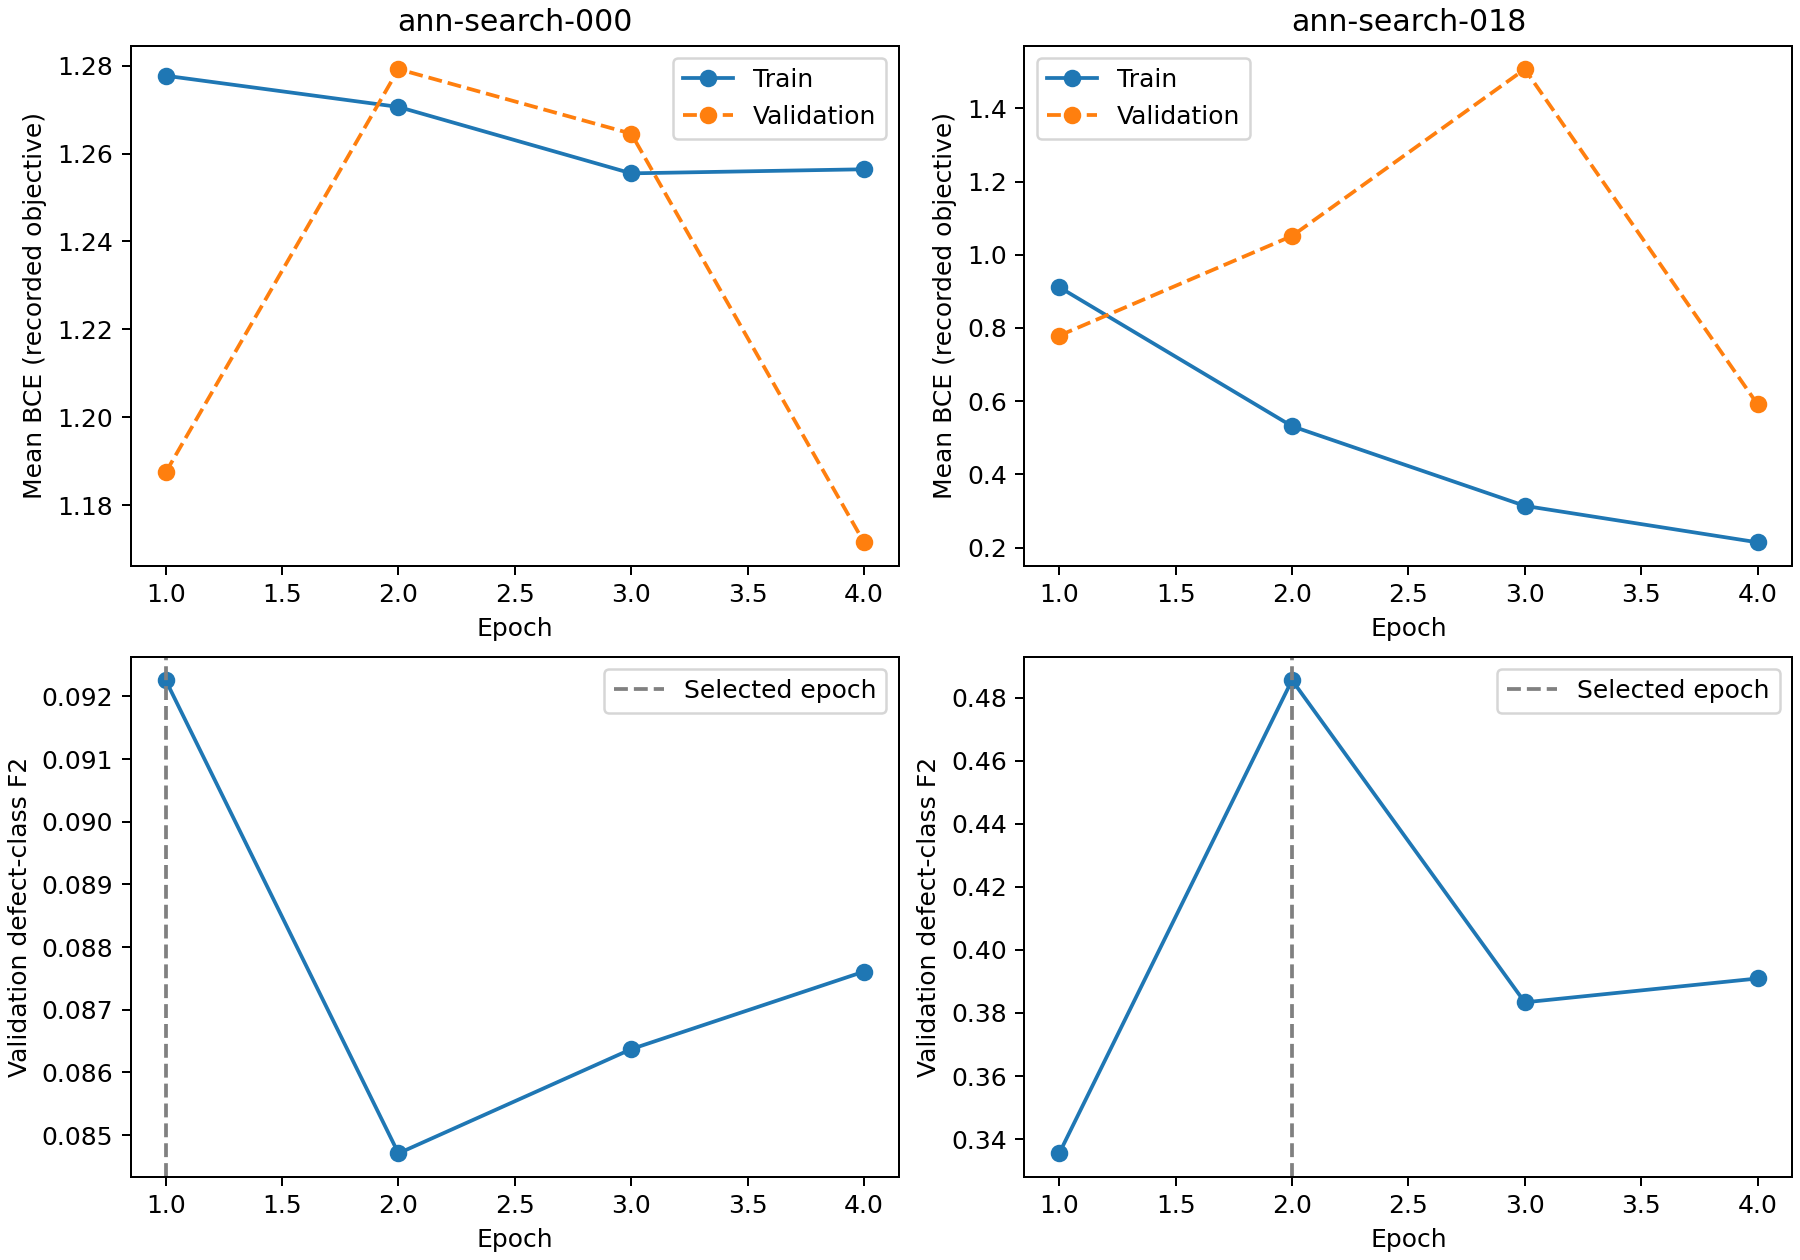

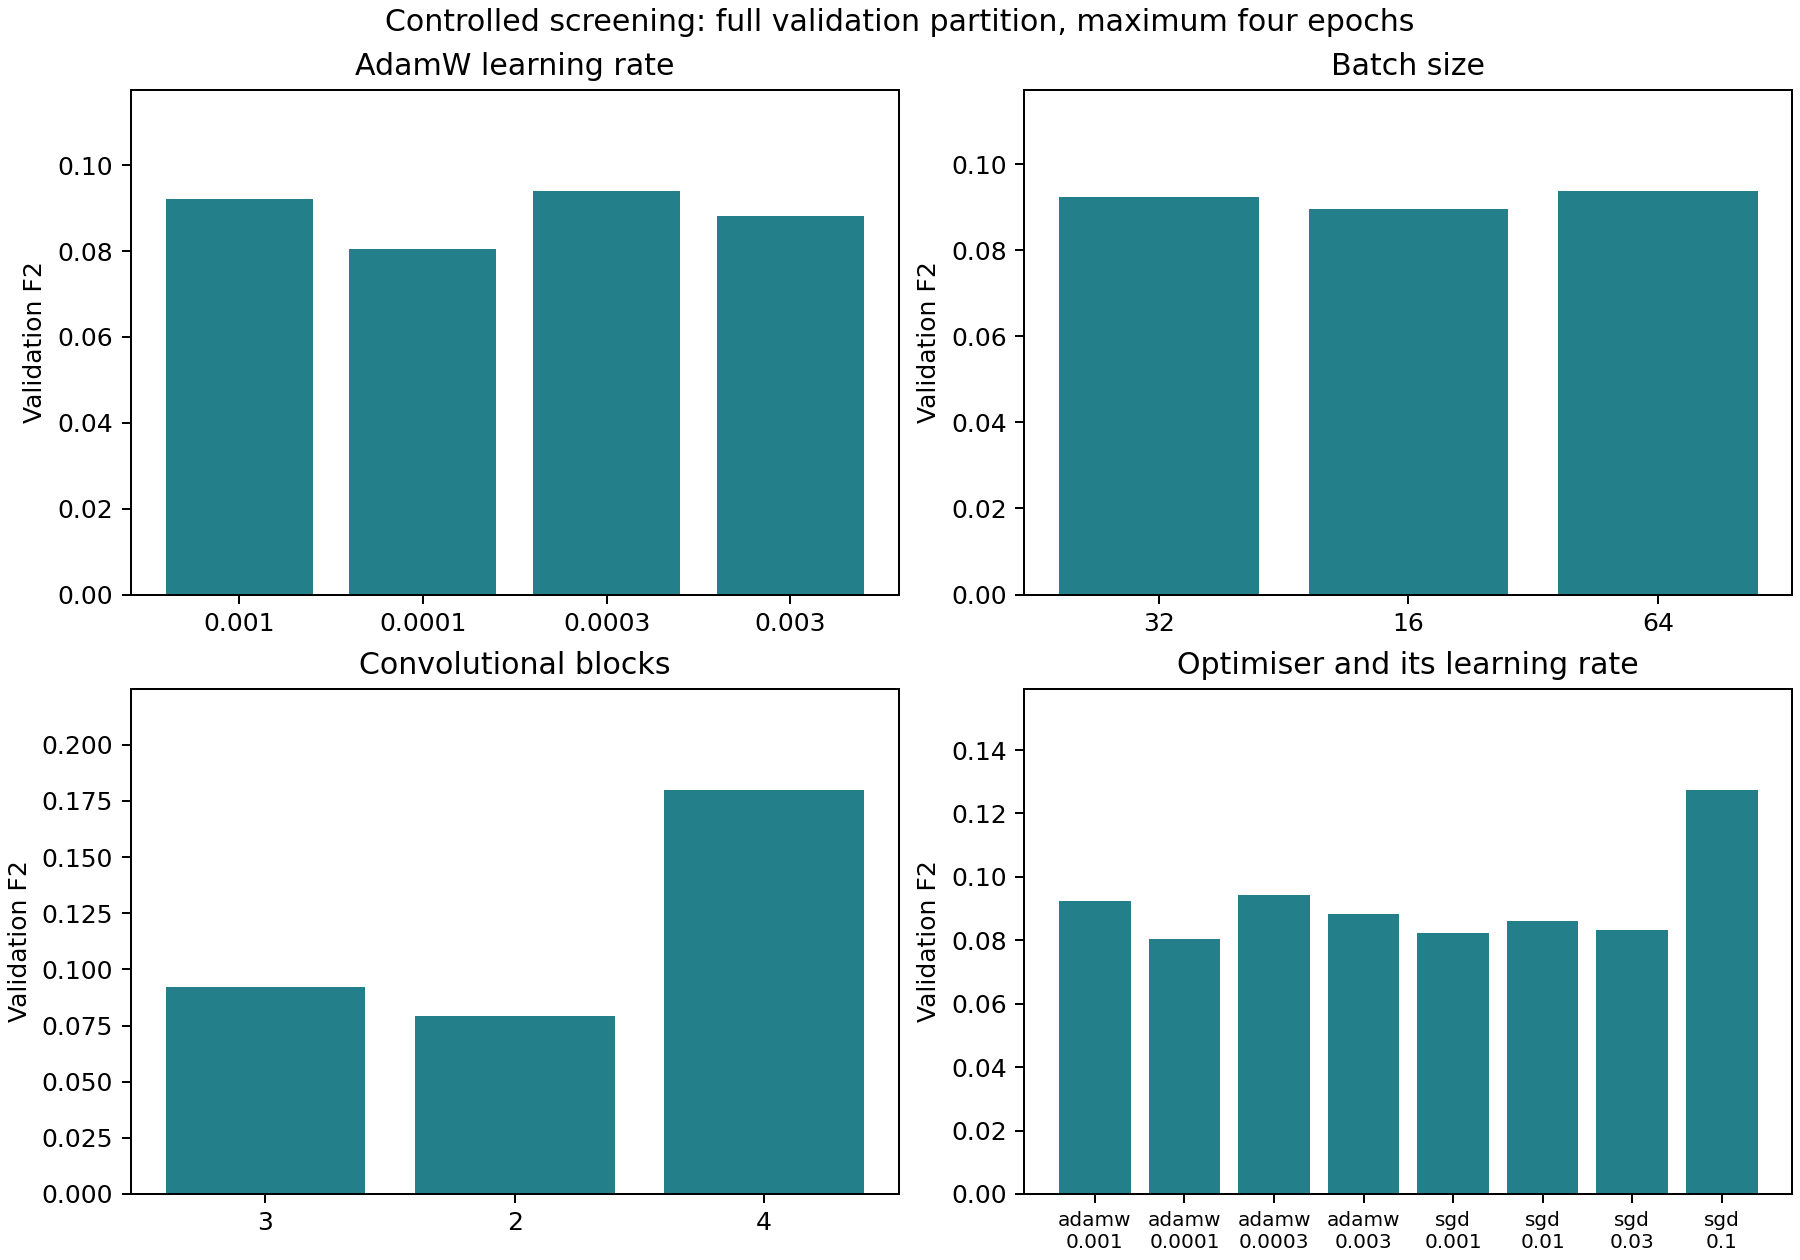

In [3]:
log=pd.read_csv(PROJECT/'reports/experiment-log.csv')
display(log)
figure('reports/figures/initial-final-learning.png')
figure('reports/figures/hyperparameter-study.png')

In [4]:
failures=read('docs/failed-approaches.json')['attempts']
assert len(failures)>=4 and sum(bool(f['substantive']) for f in failures)>=2
for case in failures:
    display(Markdown('**'+case['run_id']+'**'))
    display(case)
display(read('artifacts/seed-variability.json'))

**svm-search-024**

{'run_id': 'svm-search-024',
 'control_run_id': 'svm-search-036',
 'substantive': True,
 'hypothesis': 'Spatial LBP alone should capture irregular weave while retaining a small feature vector.',
 'evidence': {'partition': 'val',
  'examples': 3472,
  'attempt_f2': 0.07395873880887505,
  'control_f2': 0.1251564455569462,
  'f2_delta': -0.05119770674807114,
  'attempt_average_precision': 0.014787699928240368,
  'control_average_precision': 0.03314777571968396,
  'attempt_tp_fp_fn': [38, 2323, 14],
  'control_tp_fp_fn': [20, 571, 32]},
 'controlled_change': '160-dimension spatial LBP versus 8260-dimension HOG plus the same LBP; same LinearSVC C=0.1, no class weighting, train-only scaler and split.',
 'diagnosis': 'The LBP-only approach ranks defects approximately at validation prevalence and creates 2323 false positives. Adding directional gradients raises average precision and F2 while reducing false positives to 571, at the expense of recall. Histograms discard gradient orientation and 

**ann-search-000**

{'run_id': 'ann-search-000',
 'control_run_id': 'svm-search-036',
 'substantive': True,
 'hypothesis': 'A small scratch CNN with weighted BCE can learn local defects from the approved training images.',
 'evidence': {'partition': 'val',
  'examples': 3472,
  'attempt_f2': 0.09225922592259225,
  'control_f2': 0.1251564455569462,
  'f2_delta': -0.032897219634353936,
  'attempt_average_precision': 0.018771645044438956,
  'control_average_precision': 0.03314777571968396,
  'attempt_tp_fp_fn': [41, 1973, 11],
  'control_tp_fp_fn': [20, 571, 32]},
 'controlled_change': 'Whole-method comparison: weighted scratch CNN versus HOG/LBP linear SVM; architecture, features and optimisation differ, so it is not a single-factor causal experiment.',
 'diagnosis': 'The initial CNN produces 1973 validation false positives and average precision 0.0188, only slightly above prevalence 0.0150. Weighted training loss falls from 1.2777 to 1.2564, and the best F2 occurs at epoch one. Within this four-epoch CPU b

**ann-search-001**

{'run_id': 'ann-search-001',
 'control_run_id': 'ann-search-000',
 'substantive': False,
 'hypothesis': 'Reducing AdamW learning rate from 0.001 to 0.0001 may stabilise training.',
 'evidence': {'partition': 'val',
  'examples': 3472,
  'attempt_f2': 0.08040201005025126,
  'control_f2': 0.09225922592259225,
  'f2_delta': -0.011857215872340995,
  'attempt_average_precision': 0.013982060201329327,
  'control_average_precision': 0.018771645044438956,
  'attempt_tp_fp_fn': [48, 2729, 4],
  'control_tp_fp_fn': [41, 1973, 11]},
 'controlled_change': 'Learning rate only; identical seed, architecture, batch size, augmentation, weighting and four-epoch budget.',
 'diagnosis': 'The lower rate raises recall but causes 2729 false positives and lower F2/AP. Training loss falls slowly from 1.3150 to 1.2657, while validation loss rises from 1.0121 to 1.2736. Within the equal short budget, conservative updates do not improve discriminative ranking. More epochs could change this; the evidence rejects t

**ann-search-003**

{'run_id': 'ann-search-003',
 'control_run_id': 'ann-search-000',
 'substantive': False,
 'hypothesis': 'Increasing AdamW learning rate from 0.001 to 0.003 may learn more useful features quickly.',
 'evidence': {'partition': 'val',
  'examples': 3472,
  'attempt_f2': 0.088134135855546,
  'control_f2': 0.09225922592259225,
  'f2_delta': -0.004125090067046255,
  'attempt_average_precision': 0.015270795652155176,
  'control_average_precision': 0.018771645044438956,
  'attempt_tp_fp_fn': [41, 2077, 11],
  'control_tp_fp_fn': [41, 1973, 11]},
 'controlled_change': 'Learning rate only; same tensor values and RNG contract. NumPy normalisation was independently verified bit-identical for all input gray levels. Thread waiting policy affects elapsed time, not the declared model configuration.',
 'diagnosis': 'The higher rate retains the same 41 true positives and 11 false negatives as the initial control but adds 104 false positives. Validation F2 peaks at epoch two and then declines, and valida

{'partition': 'val',
 'split_sha256': 'af7daf13d0854ceeba004f1a06182bac778ac716021dec3d8fc40edf265aa76f',
 'provenance': 'RAW-FABRID_V1',
 'run_ids': ['ann-search-018', 'ann-repeat-123', 'ann-repeat-2026'],
 'seeds': [42, 123, 2026],
 'f2': [0.4856115107913669, 0.37037037037037035, 0.45267489711934156],
 'mean': 0.4362189260936929,
 'sample_std': 0.05935679698383919,
 'range': 0.11524114042099654,
 'material_variability_rule': 'F2 range > 0.02 (predeclared coursework heuristic)',
 'material': True,
 'final_test_protocol': 'Evaluate all three frozen repetitions in one final evaluation; report mean/spread. Do not choose a seed from test results.'}

In [5]:
comparison=read('reports/final-evaluation/comparison.json')
assert comparison['status']=='COMPLETE'
display(pd.DataFrame([{'model':r['model'],**r['metrics']} for r in comparison['comparisons']]))
display(read('reports/error-analysis.json'))

,model,n,tp,tn,fp,fn,precision,recall,f1,f2,accuracy,false_positive_rate,unresolved_count,average_precision,roc_auc
0,always_normal,2996,0,2900,0,96,0.000000,0.000000,0.000000,0.000000,0.967957,0.000000,0,NaN,NaN
1,always_defective,2996,96,0,2900,0,0.032043,1.000000,0.062096,0.142012,0.032043,1.000000,0,NaN,NaN
2,initial_ann,2996,0,2900,0,96,0.000000,0.000000,0.000000,0.000000,0.967957,0.000000,0,0.037934,0.492708
3,final_ann,2996,68,2858,42,28,0.618182,0.708333,0.660194,0.688259,0.976636,0.014483,0,0.718521,0.898912
4,classical,2996,5,2888,12,91,0.294118,0.052083,0.088496,0.062344,0.965621,0.004138,0,0.101425,0.612662
5,vlm,2996,94,0,2900,2,0.031396,0.979167,0.060841,0.139136,0.031375,1.000000,48,NaN,NaN


{'timestamp': '2026-10-12T06:23:12.072713+00:00',
 'posthoc_only': True,
 'selection_changed': False,
 'run_id': 'ann-search-018',
 'all_test_examples': 2996,
 'publisher_origin_metrics': [{'publisher_origin': 'Rollo1A',
   'n': 2436,
   'tp': 38,
   'tn': 2354,
   'fp': 29,
   'fn': 15,
   'precision': 0.5671641791044776,
   'recall': 0.7169811320754716,
   'f1': 0.6333333333333333,
   'f2': 0.6810035842293907,
   'accuracy': 0.9819376026272578,
   'false_positive_rate': 0.012169534200587495,
   'unresolved_count': 0,
   'average_precision': 0.7068637314077789,
   'roc_auc': 0.9116620084086177},
  {'publisher_origin': 'Rollo3A',
   'n': 560,
   'tp': 30,
   'tn': 504,
   'fp': 13,
   'fn': 13,
   'precision': 0.6976744186046512,
   'recall': 0.6976744186046512,
   'f1': 0.6976744186046512,
   'f2': 0.6976744186046512,
   'accuracy': 0.9535714285714286,
   'false_positive_rate': 0.025145067698259187,
   'unresolved_count': 0,
   'average_precision': 0.7502914487012046,
   'roc_auc': 0.

The search covers learning rate, batch size, actual convolutional depth and AdamW versus momentum SGD. Numerical effects are bounded by the four-epoch screening budget. The complete logs include all unsuccessful measured runs and separate engineering interruptions. The family comparison is reported without changing the frozen split or choosing another seed on test scores.